# 04 · Evaluación final e interpretabilidad — HU-08

1. Se reconstruye el **modelo ganador** del notebook 03 y se ajusta con todo train.
2. El **test se usa una sola vez**, con el umbral elegido en train (predicciones out-of-fold).
3. Interpretación: importancia global, efecto de las variables y dos pacientes concretos.
4. Se exportan los artefactos que consume `app.py`.

In [1]:
import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.inspection import PartialDependenceDisplay
from sklearn.metrics import roc_auc_score

from src.data import load_dataset, split_train_test
from src.evaluation import (
    compute_metrics,
    global_importance,
    local_occlusion,
    plot_confusion,
    plot_roc_pr,
    shap_available,
    shap_explanation,
)
from src.features import engineer
from src.models import get_models

sns.set_theme(style="whitegrid")
FIG = "../reports/figures/"
pd.set_option("display.width", 140)

winner = json.load(open("../artifacts/winner.json", encoding="utf-8"))
print(winner)

{'modelo': 'GBM (ajustado)', 'umbral': 0.5599999999999999, 'gbm_backend': 'sklearn-hist-gradient-boosting', 'gbm_best_params': {'model__min_samples_leaf': 20, 'model__max_leaf_nodes': 31, 'model__max_iter': 100, 'model__max_features': 0.5, 'model__learning_rate': 0.1, 'model__l2_regularization': 10}}

## 1. Reconstruir y ajustar el ganador (solo con train)

In [2]:
X, y = load_dataset()
X = engineer(X)
X_train, X_test, y_train, y_test = split_train_test(X, y)

models = get_models()
base = {"GBM (defecto)": "GBM", "GBM (ajustado)": "GBM"}.get(winner["modelo"], winner["modelo"])
pipe = models[base]
if winner["modelo"] == "GBM (ajustado)":
    pipe = pipe.set_params(**winner["gbm_best_params"])
pipe.fit(X_train, y_train)
print("Modelo final:", winner["modelo"], "| umbral (de CV en train):", winner["umbral"])

Modelo final: GBM (ajustado) | umbral (de CV en train): 0.5599999999999999

## 2. Evaluación en test (única vez)

In [3]:
proba = pipe.predict_proba(X_test)[:, 1]
m = compute_metrics(y_test, proba, winner["umbral"])
metrics = pd.DataFrame([{"modelo": winner["modelo"], **m}])
print(metrics.round(4).to_string(index=False))

rng = np.random.default_rng(42)
idx = np.arange(len(y_test))
boots = []
for _ in range(300):
    b = rng.choice(idx, len(idx))
    boots.append(roc_auc_score(y_test.iloc[b], proba[b]))
lo, hi = np.percentile(boots, [2.5, 97.5])
print(f"\nROC-AUC test = {m['roc_auc']:.4f}  (IC 95 % bootstrap: {lo:.4f} - {hi:.4f})")

# Cuánto "riesgo" concentra el 10 % de pacientes con mayor probabilidad
top = np.argsort(-proba)[: len(proba) // 10]
lift = y_test.iloc[top].mean() / y_test.mean()
print(f"Tasa de reingreso en el 10 % de mayor riesgo: {y_test.iloc[top].mean():.1%} "
      f"(base {y_test.mean():.1%}) → lift {lift:.2f}x")

        modelo  roc_auc  pr_auc  recall  precision     f1  threshold
GBM (ajustado)   0.6528   0.184  0.3976     0.1785 0.2464       0.56

ROC-AUC test = 0.6528  (IC 95 % bootstrap: 0.6375 - 0.6700)
Tasa de reingreso en el 10 % de mayor riesgo: 22.9% (base 9.0%) → lift 2.55x

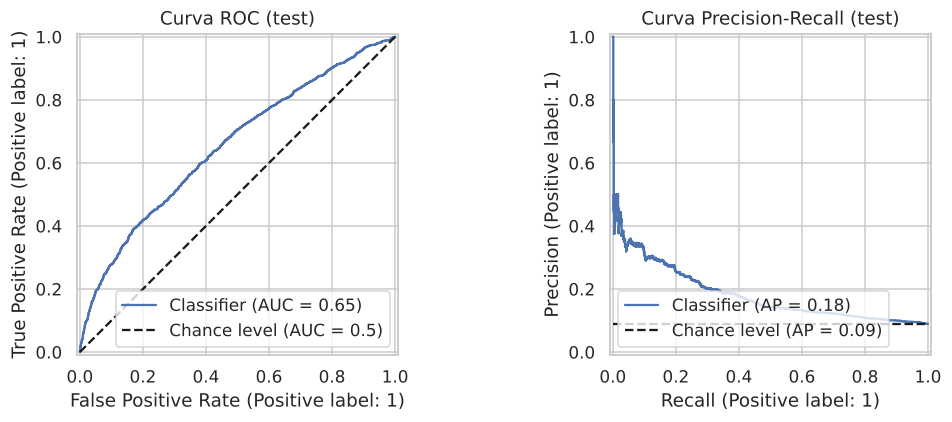

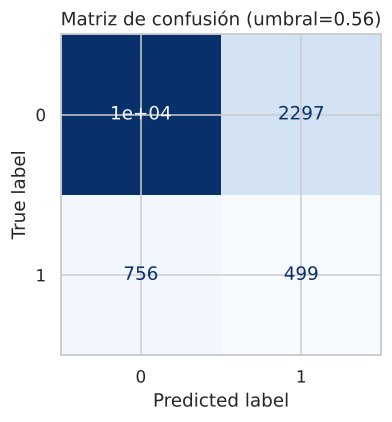

In [4]:
plot_roc_pr(y_test, proba, FIG + "roc_pr_test.png")
plot_confusion(y_test, proba, winner["umbral"], FIG + "confusion_test.png")

### Lectura de la matriz de confusión
El umbral (0.56) maximiza F1 sobre las predicciones out-of-fold de train. En test el modelo detecta
~40 % de los reingresos (recall 0.40) con una precisión de ~0.18: de cada 100 alertas, ~18 son
reingresos reales frente a una tasa base del 9 %. Es decir, **prioriza** pacientes (lift ≈ 2.5x en
el 10 % de mayor riesgo) pero **no** es un clasificador preciso: muchas falsas alarmas.

> **Ojo:** al entrenar con `class_weight="balanced"` el puntaje del modelo **no es una
> probabilidad calibrada** (un puntaje de 0.56 no significa 56 % de riesgo real). Sirve para
> ordenar pacientes y compararlos con el umbral, no para leerlo como probabilidad.

## 3. Interpretabilidad global

In [5]:
USE_SHAP = shap_available() and winner["modelo"] in ("GBM (defecto)", "GBM (ajustado)") \
    and winner["gbm_backend"] == "lightgbm"
print("SHAP disponible y aplicable:", USE_SHAP)

SHAP disponible y aplicable: False

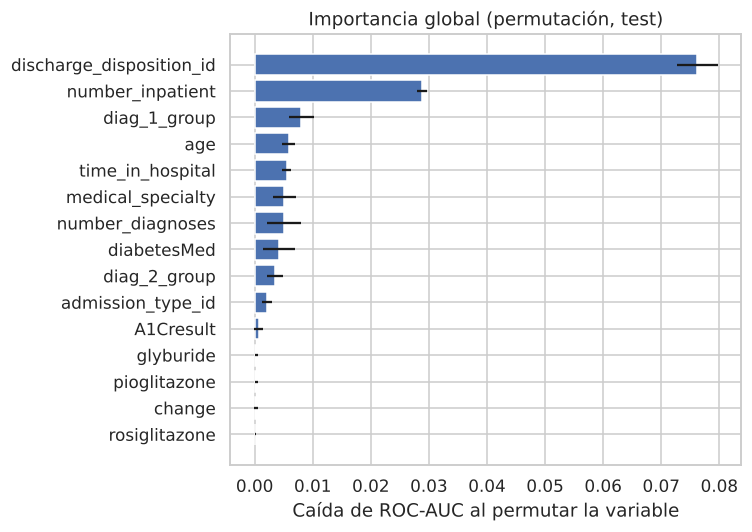

In [6]:
if USE_SHAP:
    import shap

    expl = shap_explanation(pipe, X_test, max_rows=2000)
    shap.summary_plot(expl.values, expl.data, feature_names=expl.feature_names, show=False)
    plt.gcf().savefig(FIG + "shap_summary.png", dpi=130, bbox_inches="tight")
else:
    # Respaldo sin `shap`: importancia por permutación (caída de ROC-AUC) por variable original
    sample = X_test.sample(5000, random_state=42)
    imp = global_importance(pipe, sample, y_test.loc[sample.index], n_repeats=3)
    top15 = imp.head(15).iloc[::-1]
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.barh(top15["feature"], top15["importance"], xerr=top15["std"], color="#4c72b0")
    ax.set_xlabel("Caída de ROC-AUC al permutar la variable")
    ax.set_title("Importancia global (permutación, test)")
    fig.tight_layout()
    fig.savefig(FIG + "importancia_global.png", dpi=130)
    imp.head(15)

La importancia mide **cuánto** pesa cada variable; para ver **en qué dirección** empuja el riesgo
se usan dependencias parciales sobre las variables más relevantes.

Variables: ['number_inpatient', 'age', 'time_in_hospital', 'number_diagnoses']

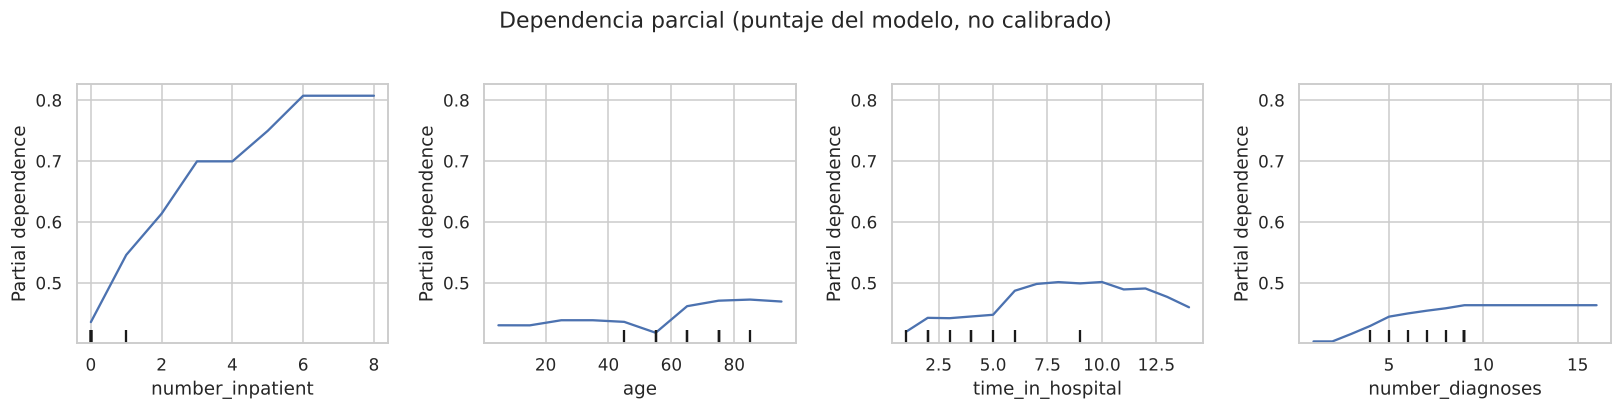

In [7]:
if not USE_SHAP:
    num_top = [f for f in imp["feature"] if pd.api.types.is_numeric_dtype(X_train[f])][:4]
    fig, ax = plt.subplots(1, 4, figsize=(15, 3.6))
    pd_sample = X_test.sample(3000, random_state=0).astype({c: float for c in num_top})
    PartialDependenceDisplay.from_estimator(
        pipe, pd_sample, num_top, ax=ax, kind="average", grid_resolution=15
    )
    fig.suptitle("Dependencia parcial (puntaje del modelo, no calibrado)", y=1.03)
    fig.tight_layout()
    fig.savefig(FIG + "dependencia_parcial.png", dpi=130, bbox_inches="tight")
    print("Variables:", num_top)

## 4. Interpretabilidad local: dos pacientes del test
Un paciente de **alto riesgo** (verdadero positivo con probabilidad máxima) y uno de **bajo riesgo**.

Paciente de alto riesgo: puntaje = 0.87
number_inpatient            1.066
discharge_disposition_id    0.436
time_in_hospital            0.190
age                         0.116
admission_source_id        -0.104
diag_2_group               -0.062

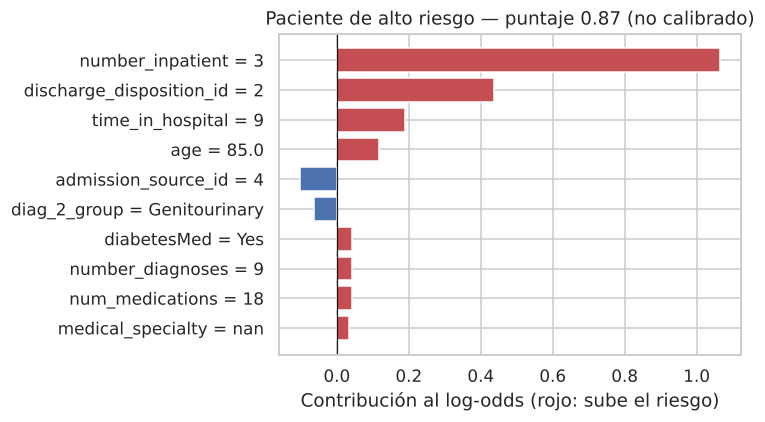

In [8]:
test = X_test.assign(proba=proba, y=y_test)
hi_idx = test[test["y"] == 1].sort_values("proba", ascending=False).index[0]
lo_idx = test[test["y"] == 0].sort_values("proba").index[0]
background = X_train.sample(150, random_state=1)


def explain(idx, title, fname):
    row = X_test.loc[[idx]]
    p = pipe.predict_proba(row)[0, 1]
    if USE_SHAP:
        e = shap_explanation(pipe, row, max_rows=1)
        shap.plots.waterfall(e[0], max_display=10, show=False)
        plt.gcf().savefig(FIG + fname, dpi=130, bbox_inches="tight")
        return
    contrib = local_occlusion(pipe, row, background)
    top = contrib.head(10).iloc[::-1]
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.barh([f"{k} = {row[k].iloc[0]}" for k in top.index], top.values,
            color=["#c44e52" if v > 0 else "#4c72b0" for v in top.values])
    ax.axvline(0, c="k", lw=0.8)
    ax.set_xlabel("Contribución al log-odds (rojo: sube el riesgo)")
    ax.set_title(f"{title} — puntaje {p:.2f} (no calibrado)")
    fig.tight_layout()
    fig.savefig(FIG + fname, dpi=130)
    print(f"{title}: puntaje = {p:.2f}")
    print(contrib.head(6).round(3).to_string())


explain(hi_idx, "Paciente de alto riesgo", "local_alto_riesgo.png")

Paciente de bajo riesgo: puntaje = 0.11
discharge_disposition_id   -0.164
medical_specialty          -0.150
time_in_hospital           -0.124
diag_1_group                0.078
A1Cresult                  -0.078
glimepiride                -0.064

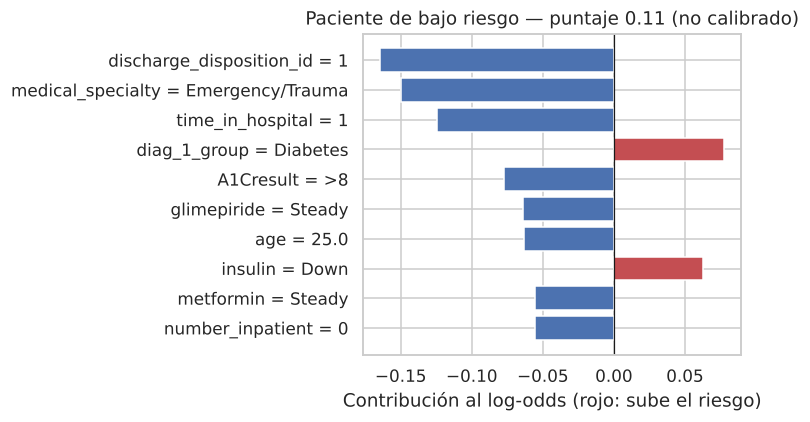

In [9]:
explain(lo_idx, "Paciente de bajo riesgo", "local_bajo_riesgo.png")

## 5. Interpretación clínica
_(Redactada con los resultados de esta ejecución, que usó el respaldo sin `shap`: importancia por
permutación, dependencia parcial y oclusión. Con `uv sync` + LightGBM el notebook genera el
summary plot y los waterfall SHAP; las conclusiones cualitativas deberían mantenerse.)_

**Qué pesa más (global).** Al permutar cada variable, las que más degradan el ROC-AUC son
`discharge_disposition_id` (≈ −0.076) y `number_inpatient` (≈ −0.029); muy por detrás vienen
`diag_1_group`, `age`, `time_in_hospital`, `medical_specialty` y `number_diagnoses` (≈ −0.005 a
−0.008 cada una). Los medicamentos individuales y `A1Cresult` casi no aportan.

**En qué dirección.**
- **Hospitalizaciones previas:** el puntaje crece de forma casi monótona con `number_inpatient`
  (de ~0.43 sin ingresos previos a ~0.80 con 6 o más). Es la señal clínica más clara: el paciente
  "frecuente" es el que vuelve.
- **Destino al alta:** quienes salen hacia otra institución (p. ej. otro hospital de corta
  estancia) reciben más riesgo que quienes se van a casa; refleja pacientes más complejos.
- **Edad:** plana hasta ~60 años y algo mayor después. **Estancia:** el riesgo sube hasta ~7-10
  días y luego baja. **Número de diagnósticos:** sube hasta ~9 y se estabiliza.

**Casos concretos.** El paciente de alto riesgo (puntaje 0.87) se explica sobre todo por 3
ingresos previos (+1.07 en log-odds), alta hacia otro hospital (+0.44), 9 días de estancia y 85
años. El de bajo riesgo (0.11) no tiene ningún factor fuerte: contribuciones pequeñas y negativas
(destino al alta, especialidad, estancia corta).

**Salvedades.** (1) Son asociaciones, no causas. (2) Las dependencias parciales promedian sobre
el resto de variables y pueden ocultar interacciones. (3) El puntaje no está calibrado (ver
sección 2). (4) La oclusión es una aproximación de primer orden a un valor de Shapley.

## 6. Exportar artefactos para la app (HU-09)

In [10]:
joblib.dump(pipe, "../artifacts/model.joblib")
metrics.to_csv("../artifacts/metrics.csv", index=False)
cv = pd.read_csv("../artifacts/cv_results.csv")
test_sample = X_test.sample(300, random_state=7).assign(target=y_test)
test_sample.to_csv("../artifacts/test_sample.csv")
X_train.sample(150, random_state=1).to_csv("../artifacts/background.csv")
print("Artefactos:", ["model.joblib", "metrics.csv", "test_sample.csv", "background.csv"])
cv.round(4)

Artefactos: ['model.joblib', 'metrics.csv', 'test_sample.csv', 'background.csv']

,modelo,roc_auc,roc_auc_std,pr_auc,pr_auc_std,recall,precision,f1,umbral,seg
0,LogReg,0.6484,0.0069,0.1646,0.0039,0.3485,0.1698,0.2283,0.58,12
1,Árbol,0.6216,0.0059,0.1490,0.0049,0.3610,0.1467,0.2086,0.56,6
2,RandomForest,0.6510,0.0054,0.1652,0.0034,0.4596,0.1509,0.2272,0.51,41
3,GBM (defecto),0.6473,0.0036,0.1689,0.0038,0.3045,0.1782,0.2249,0.58,13
4,GBM (ajustado),0.6532,0.0065,0.1707,0.0031,0.3714,0.1671,0.2304,0.56,15
